In [21]:
import numpy as np
from sympy import *
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

In [11]:
# Growth rates (per hour)
r_s = 0.4
r_p = 0.3

# Carrying capacity ratios
K_ratios = [1, 10, 100, 1000, 10000]
K_s = 1
K_p = 1
# Competition coefficients
alpha_sp = 5.893
alpha_ps = 1.860

In [ ]:
# Parameters
r_s, r_p, K_s, K_p, alpha_sp, alpha_ps = symbols(
    'r_s r_p K_s K_p alpha_sp alpha_ps', positive=True
)

S, P = symbols('S P')

# Numerical values
params = {
    r_s: 0.4,
    r_p: 0.3,
    K_s: 1,
    K_p: 1,
    alpha_sp: 5.893,
    alpha_ps: 1.860,
}

# Jacobian entries
J11 = r_s - (r_s / K_s) * (2*S + alpha_sp*P)
J12 = -r_s * alpha_sp * S / K_s
J21 = -r_p * alpha_ps * P / K_p
J22 = r_p - (r_p / K_p) * (2*P + alpha_ps*S)

J = Matrix([[J11, J12], [J21, J22]])

# Coexistence fixed point
S_star = (K_s - alpha_sp*K_p) / (1 - alpha_sp*alpha_ps)
P_star = (K_p - alpha_ps*K_s) / (1 - alpha_sp*alpha_ps)

fixed_points = {
    "(0, 0)":       {S: 0,      P: 0},
    "(K_s, 0)":     {S: K_s,   P: 0},
    "(0, K_p)":     {S: 0,     P: K_p},
    "(S*, P*)":     {S: S_star, P: P_star},
}

for name, point in fixed_points.items():
    print(f"\n--- Fixed point {name} ---")
    
    # Substitute fixed point, then numerical params
    J_eval = J.subs(point).subs(params)
    J_num = matrix2numpy(J_eval, dtype=float)
    
    eigenvalues = np.linalg.eigvals(J_num)
    print("Eigenvalues:", eigenvalues)

    det = eigenvalues[0] * eigenvalues[1]
    print("Determinant:", det)
    tr = eigenvalues[0] + eigenvalues[1]
    print("Trace:      ", tr)
    discriminant = tr**2 - 4*det
    print("Discriminant:", discriminant)
    if det <0:
        stability = "Saddle"
    elif det > 0:
        if discriminant < 0:
            if tr < 0:
                stability = "Stable Spiral"
            elif tr > 0:
                stability = "Unstable Spiral"
        if discriminant > 0:
            if tr > 0:
                stability = "Unstable Node"
            elif tr < 0:
                stability = "Stable Node"
            elif discriminant == 0:
                stability = "Degenerate Node"
            elif tr == 0:
                stability = "Center"
    if discriminant == 0:
        stability = "Non-isolated fixed points"
    print("Stability:  ", stability)


--- Fixed point (0, 0) ---
Eigenvalues: [0.4 0.3]
Determinant: 0.12
Trace:       0.7
Discriminant: 0.009999999999999953
Stability:   Unstable Node

--- Fixed point (K_s, 0) ---
Eigenvalues: [-0.4   -0.258]
Determinant: 0.10320000000000001
Trace:       -0.658
Discriminant: 0.02016399999999996
Stability:   Stable Node

--- Fixed point (0, K_p) ---
Eigenvalues: [-0.3    -1.9572]
Determinant: 0.58716
Trace:       -2.2572
Discriminant: 2.74631184
Stability:   Stable Node

--- Fixed point (S*, P*) ---
Eigenvalues: [-0.36230669  0.13991893]
Determinant: -0.05069356629568576
Trace:       -0.22238775702792285
Discriminant: 0.2522305796586535
Stability:   Saddle


In [20]:
for name, point in fixed_points.items():
    print("Fixed point:", name)
    J_eval2 = simplify(J.subs(point))
    display(J_eval2)
    eigenvalues = J_eval2.eigenvals()
    for eigenvalue, multiplicity in eigenvalues.items():
        print("Eigenvalue:", eigenvalue, "Multiplicity:", multiplicity)

    trace = simplify(J_eval2.trace())
    determinant = simplify(J_eval2.det())
    print("Trace:")
    display(trace)
    print("Determinant:")
    display(determinant)

Fixed point: (0, 0)


Matrix([
[r_s,   0],
[  0, r_p]])

Eigenvalue: r_s Multiplicity: 1
Eigenvalue: r_p Multiplicity: 1
Trace:


r_p + r_s

Determinant:


r_p*r_s

... (14 outputs left out)

Eigenvalue: -(K_p**2*alpha_sp*r_s - K_p*K_s*r_p - K_p*K_s*r_s + K_s**2*alpha_ps*r_p)/(2*K_p*K_s*(alpha_ps*alpha_sp - 1)) - sqrt(K_p**4*alpha_sp**2*r_s**2 - 4*K_p**3*K_s*alpha_ps*alpha_sp**2*r_p*r_s + 2*K_p**3*K_s*alpha_sp*r_p*r_s - 2*K_p**3*K_s*alpha_sp*r_s**2 + 4*K_p**2*K_s**2*alpha_ps**2*alpha_sp**2*r_p*r_s + 2*K_p**2*K_s**2*alpha_ps*alpha_sp*r_p*r_s + K_p**2*K_s**2*r_p**2 - 2*K_p**2*K_s**2*r_p*r_s + K_p**2*K_s**2*r_s**2 - 4*K_p*K_s**3*alpha_ps**2*alpha_sp*r_p*r_s - 2*K_p*K_s**3*alpha_ps*r_p**2 + 2*K_p*K_s**3*alpha_ps*r_p*r_s + K_s**4*alpha_ps**2*r_p**2)/(2*K_p*K_s*(alpha_ps*alpha_sp - 1)) Multiplicity: 1
Eigenvalue: -(K_p**2*alpha_sp*r_s - K_p*K_s*r_p - K_p*K_s*r_s + K_s**2*alpha_ps*r_p)/(2*K_p*K_s*(alpha_ps*alpha_sp - 1)) + sqrt(K_p**4*alpha_sp**2*r_s**2 - 4*K_p**3*K_s*alpha_ps*alpha_sp**2*r_p*r_s + 2*K_p**3*K_s*alpha_sp*r_p*r_s - 2*K_p**3*K_s*alpha_sp*r_s**2 + 4*K_p**2*K_s**2*alpha_ps**2*alpha_sp**2*r_p*r_s + 2*K_p**2*K_s**2*alpha_ps*alpha_sp*r_p*r_s + K_p**2*K_s**2*r_p**2 - 2*K_p

(-K_p*r_s*(K_p*alpha_sp - K_s) + K_s*r_p*(K_p - K_s*alpha_ps))/(K_p*K_s*(alpha_ps*alpha_sp - 1))

Determinant:


r_p*r_s*(K_p**2*alpha_sp - K_p*K_s*alpha_ps*alpha_sp - K_p*K_s + K_s**2*alpha_ps)/(K_p*K_s*(alpha_ps*alpha_sp - 1))

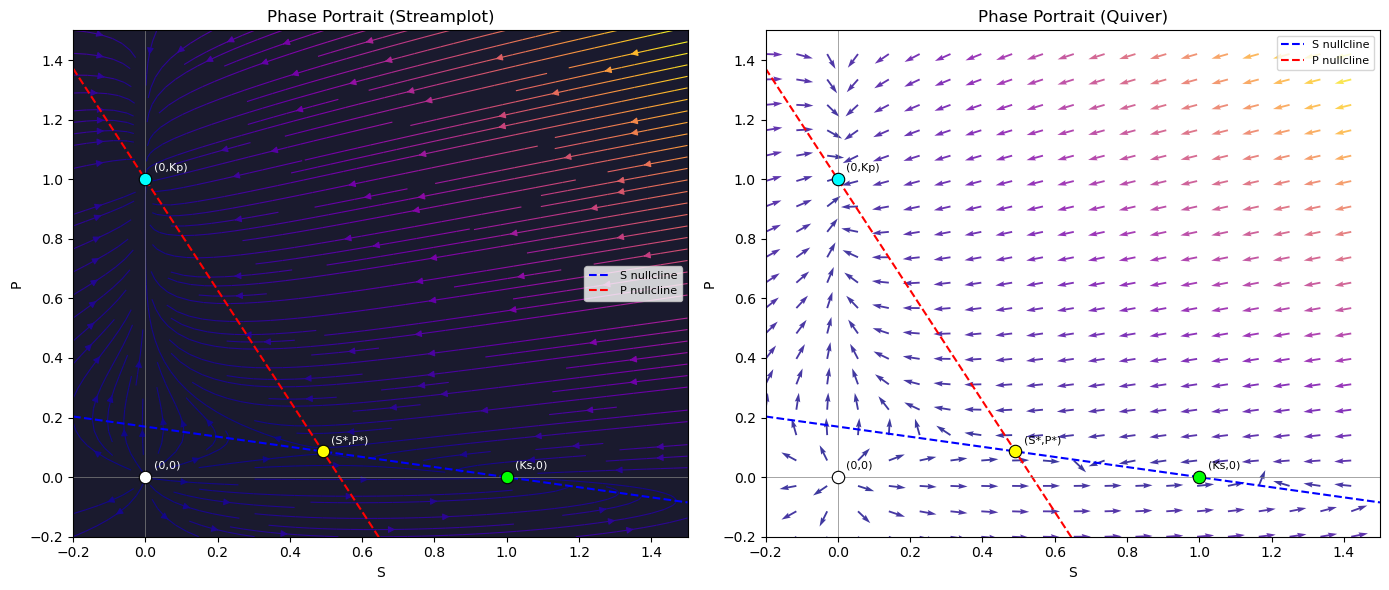

In [26]:

# Numerical parameters
r_s_n = 0.4
r_p_n = 0.3
K_s_n = 1
K_p_n = 1
alpha_sp_n = 5.893
alpha_ps_n = 1.860

# Fixed points (numerical)
S_star_n = (K_s_n - alpha_sp_n * K_p_n) / (1 - alpha_sp_n * alpha_ps_n)
P_star_n = (K_p_n - alpha_ps_n * K_s_n) / (1 - alpha_sp_n * alpha_ps_n)

fixed_pts = {
    "(0,0)":      (0, 0),
    "(Ks,0)":     (K_s_n, 0),
    "(0,Kp)":     (0, K_p_n),
    "(S*,P*)":    (S_star_n, P_star_n),
}

# Grid
S_vals = np.linspace(-0.2, 1.5, 300)
P_vals = np.linspace(-0.2, 1.5, 300)
S_grid, P_grid = np.meshgrid(S_vals, P_vals)

dS = r_s_n * S_grid * (1 - (S_grid + alpha_sp_n * P_grid) / K_s_n)
dP = r_p_n * P_grid * (1 - (P_grid + alpha_ps_n * S_grid) / K_p_n)

# Normalize for streamplot arrows
magnitude = np.sqrt(dS**2 + dP**2)
magnitude[magnitude == 0] = 1  # avoid division by zero

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Plot 1: Streamplot ---
ax1 = axes[0]
ax1.streamplot(S_vals, P_vals, dS, dP, color=magnitude,
               cmap='plasma', linewidth=0.8, density=1.5)

# Nullclines
# S nullcline: S=0 or S + alpha_sp*P = K_s => P = (K_s - S)/alpha_sp
P_null_S = (K_s_n - S_vals) / alpha_sp_n
# P nullcline: P=0 or P + alpha_ps*S = K_p => P = K_p - alpha_ps*S
P_null_P = K_p_n - alpha_ps_n * S_vals

ax1.plot(S_vals, P_null_S, 'b--', label='S nullcline', linewidth=1.5)
ax1.plot(S_vals, P_null_P, 'r--', label='P nullcline', linewidth=1.5)

# Fixed points
colors = {'(0,0)': 'white', '(Ks,0)': 'lime', '(0,Kp)': 'cyan', '(S*,P*)': 'yellow'}
for label, (sx, px) in fixed_pts.items():
    ax1.scatter(sx, px, s=80, zorder=5, color=colors[label], edgecolors='black', linewidths=0.8)
    ax1.annotate(label, (sx, px), textcoords="offset points",
                 xytext=(6, 6), fontsize=8, color='white')

ax1.set_xlim(-0.2, 1.5)
ax1.set_ylim(-0.2, 1.5)
ax1.set_xlabel('S')
ax1.set_ylabel('P')
ax1.set_title('Phase Portrait (Streamplot)')
ax1.legend(fontsize=8)
ax1.axhline(0, color='gray', linewidth=0.5)
ax1.axvline(0, color='gray', linewidth=0.5)
ax1.set_facecolor('#1a1a2e')

# --- Plot 2: Quiver ---
ax2 = axes[1]
skip = 15
ax2.quiver(S_grid[::skip, ::skip], P_grid[::skip, ::skip],
           dS[::skip, ::skip] / magnitude[::skip, ::skip],
           dP[::skip, ::skip] / magnitude[::skip, ::skip],
           magnitude[::skip, ::skip], cmap='plasma', alpha=0.8)

ax2.plot(S_vals, P_null_S, 'b--', label='S nullcline', linewidth=1.5)
ax2.plot(S_vals, P_null_P, 'r--', label='P nullcline', linewidth=1.5)

for label, (sx, px) in fixed_pts.items():
    ax2.scatter(sx, px, s=80, zorder=5, color=colors[label], edgecolors='black', linewidths=0.8)
    ax2.annotate(label, (sx, px), textcoords="offset points",
                 xytext=(6, 6), fontsize=8)

ax2.set_xlim(-0.2, 1.5)
ax2.set_ylim(-0.2, 1.5)
ax2.set_xlabel('S')
ax2.set_ylabel('P')
ax2.set_title('Phase Portrait (Quiver)')
ax2.legend(fontsize=8)
ax2.axhline(0, color='gray', linewidth=0.5)
ax2.axvline(0, color='gray', linewidth=0.5)

plt.tight_layout()
plt.show()